# Prédire le défaut de paiement : tour d'horizon des méthodes de machine learning

Ce notebook prolonge le notebook d'exploration et de nettoyage. Pour pouvoir suivre la démarche ici, on reprend d'abord la **préparation des données, étape par étape**, en expliquant chaque choix. On essaie ensuite plusieurs méthodes de machine learning sur le même problème, on comprend comment chacune fonctionne, puis on cherche à les améliorer.

**Le problème.** Pour chaque client d'une banque taïwanaise, on veut prédire s'il sera en **défaut de paiement** le mois suivant (1) ou non (0), à partir de son profil et de son historique de paiement sur six mois. C'est un problème de **classification binaire**.

**Plan.**

1. Préparer les données pas à pas : lire, vérifier, nettoyer, encoder et réserver le test
2. Savoir évaluer un modèle
3. Deux points de comparaison simples
4. Huit méthodes de machine learning, une par une
5. Améliorer les modèles : nouvelles variables, réglages, combinaison de modèles, choix du seuil
6. Évaluation finale sur des données jamais vues
7. Comprendre ce que le modèle a appris
8. Récapitulatif

Pour chaque méthode, on suit le même plan : l'idée, une image pour la comprendre, les réglages importants, le code, puis la lecture des résultats.

### Petit vocabulaire

| Terme | Signification |
|---|---|
| Modèle | Un programme qui apprend, à partir d'exemples, à faire une prédiction |
| Variable (ou *feature*) | Une information sur le client utilisée par le modèle (âge, plafond…) |
| Cible | Ce qu'on veut prédire : ici `DEFAULT` |
| Entraîner (*fit*) | Montrer des exemples au modèle pour qu'il apprenne |
| Prédire (*predict*) | Utiliser le modèle entraîné sur de nouveaux clients |
| Hyperparamètre | Un réglage du modèle choisi par nous avant l'entraînement (par exemple, la profondeur d'un arbre) |
| Surapprentissage (*overfitting*) | Le modèle apprend ses exemples par cœur et se trompe sur les nouveaux |

## 0. Import des bibliothèques

Tout le machine learning se fait avec `scikit-learn`. Chaque méthode y est une classe qui s'utilise toujours de la même façon : on crée le modèle, on l'entraîne avec `.fit(X, y)`, puis on prédit avec `.predict(X)` ou `.predict_proba(X)`. Une fois qu'on a compris ce schéma pour une méthode, on sait utiliser toutes les autres.

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Préparation et évaluation
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_predict,
                                     RandomizedSearchCV, learning_curve)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

# Les modèles
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              VotingClassifier)
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)

SEED = 42          # graine aléatoire : mêmes résultats à chaque exécution
BLEU, ROUGE = '#3B6FB6', '#C8423B'

# 1. Préparer les données pas à pas

Avant d'entraîner un modèle, il faut comprendre ce que représente chaque colonne et transformer le tableau en entrées utilisables. On reprend ici les traitements du notebook précédent, avec une cellule de code par étape pour voir leur effet.

**Notre point de départ :** un fichier Excel dans lequel une ligne représente un client. **Notre point d'arrivée :** quatre objets, `X_train`, `X_test`, `y_train` et `y_test`, qui serviront à apprendre puis à évaluer les modèles.

**Le chemin suivi :** charger → vérifier → retirer l'identifiant → traiter les lignes identiques → regrouper certains codes → encoder les catégories → séparer les entrées et la cible → réserver le test.

## 1.1 Charger le fichier et clarifier les noms

**Ce que l'on fait.** On lit le fichier Excel avec `pd.read_excel`. Il possède deux lignes d'en-tête : `header=1` indique que les noms des colonnes se trouvent sur la deuxième ligne, car Python compte à partir de zéro.

On renomme ensuite deux colonnes :

- `default payment next month` devient **`DEFAULT`**, la cible : `1` signifie un défaut le mois suivant et `0` une absence de défaut ;
- `PAY_0` devient **`PAY_1`**, le statut de remboursement de septembre, pour aligner sa numérotation avec `BILL_AMT1` et `PAY_AMT1`. Les mois suivants dans les noms remontent vers le passé : `2` = août, jusqu'à `6` = avril.

On garde une copie brute, `df_brut`, pour pouvoir revenir au fichier de départ. `head()` permet de vérifier que la lecture et les noms des colonnes sont corrects.

In [2]:
df_brut = pd.read_excel('data/default of credit card clients.xls', header=1)
df = df_brut.rename(columns={
    'PAY_0': 'PAY_1',
    'default payment next month': 'DEFAULT',
}).copy()

print(f'Fichier chargé : {df.shape[0]} lignes et {df.shape[1]} colonnes')
display(df.head())

Fichier chargé : 30000 lignes et 25 colonnes


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 1.2 Comprendre les variables et contrôler le tableau

Les 25 colonnes de départ jouent des rôles différents :

| Colonnes | Ce qu'elles représentent | Comment les lire |
|---|---|---|
| `ID` | Identifiant du client | Une clé pour retrouver une ligne |
| `LIMIT_BAL` | Plafond de crédit | Montant en nouveaux dollars taïwanais (NT$) |
| `SEX`, `EDUCATION`, `MARRIAGE` | Sexe, niveau d'études, situation matrimoniale | Des codes de catégories, pas des quantités |
| `AGE` | Âge | Nombre d'années |
| `PAY_1` à `PAY_6` | Statuts de remboursement sur six mois | Les codes positifs indiquent des mois de retard |
| `BILL_AMT1` à `BILL_AMT6` | Montants des relevés mensuels | Montants en NT$ |
| `PAY_AMT1` à `PAY_AMT6` | Paiements effectués chaque mois | Montants en NT$ |
| `DEFAULT` | Défaut le mois suivant | Réponse à prédire : 0 ou 1 |

**Ce que l'on vérifie.** La taille du tableau, les types, les valeurs manquantes, l'unicité de l'identifiant et les valeurs de la cible. Un type entier ne suffit pas à dire qu'une variable est une quantité : `EDUCATION=2` désigne une catégorie.

**Pourquoi.** Ces contrôles permettent de repérer un problème de lecture ou une donnée absente avant de modifier le tableau. Ici, le fichier ne contient pas de valeurs manquantes : on n'a donc rien à remplacer. Les zéros et les codes négatifs ne sont pas automatiquement des valeurs manquantes.

In [3]:
controle = pd.DataFrame({
    'Type': df.dtypes.astype(str),
    'Valeurs manquantes': df.isna().sum(),
    'Valeurs distinctes': df.nunique(),
})
display(controle)
print(f'Identifiants tous uniques : {df["ID"].is_unique}')
print(f'Valeurs de la cible : {sorted(df["DEFAULT"].unique())}')
print(f'Total de valeurs manquantes : {df.isna().sum().sum()}')

,Type,Valeurs manquantes,Valeurs distinctes
ID,int64,0,30000
LIMIT_BAL,int64,0,81
SEX,int64,0,2
EDUCATION,int64,0,7
MARRIAGE,int64,0,4
AGE,int64,0,56
PAY_1,int64,0,11
PAY_2,int64,0,11
PAY_3,int64,0,11
PAY_4,int64,0,11


Identifiants tous uniques : True
Valeurs de la cible : [np.int64(0), np.int64(1)]
Total de valeurs manquantes : 0


## 1.3 Retirer l'identifiant

**Ce que l'on fait.** On supprime la colonne `ID` des données utilisées pour la prédiction.

**Pourquoi.** Ce numéro identifie un client dans le fichier ; ce n'est pas une mesure de son comportement de remboursement. Le laisser dans les entrées pourrait faire apprendre au modèle un lien lié à la numérotation du fichier.

On passe de **25 à 24 colonnes** : 23 caractéristiques du client et la cible `DEFAULT`.

In [4]:
df = df.drop(columns='ID')
print(f'Après retrait de ID : {df.shape[0]} lignes et {df.shape[1]} colonnes')

Après retrait de ID : 30000 lignes et 24 colonnes


## 1.4 Repérer et traiter les lignes identiques

**Ce que l'on fait.** Après le retrait de `ID`, on compte les lignes entièrement identiques, puis on n'en conserve qu'une par groupe avec `drop_duplicates()`. Le comptage inclut la cible `DEFAULT`. `reset_index(drop=True)` renumérote simplement les lignes restantes.

**Pourquoi après le retrait de `ID` ?** Deux lignes avec des identifiants différents ne peuvent pas être identiques tant que cette colonne est présente. Sur ce fichier, on retire **35 répétitions**, ce qui laisse **29 965 lignes**.

**Choix repris de ce notebook.** Deux lignes identiques peuvent aussi correspondre à des clients distincts : leur égalité ne prouve pas une erreur de saisie. Ici, on conserve le choix de dédoublonnage du support initial. Cela ne garantit pas que tous les profils explicatifs identiques seront séparés du test : pour cette garantie, il faudrait les conserver ensemble lors du découpage, comme dans le notebook de démarche d'ingénieur.

In [5]:
n_avant = len(df)
n_repetitions = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

print(f'Lignes avant : {n_avant}')
print(f'Répétitions retirées : {n_repetitions}')
print(f'Lignes restantes : {len(df)}')

Lignes avant : 30000
Répétitions retirées : 35
Lignes restantes : 29965


## 1.5 Regrouper certains codes de catégories

**Ce que l'on fait.** On observe les codes présents dans `EDUCATION` et `MARRIAGE`, puis on reprend les regroupements du notebook initial :

| Variable | Codes non documentés regroupés | Catégorie de destination |
|---|---|---|
| `EDUCATION` | `0`, `5`, `6` | `4`, « autre » |
| `MARRIAGE` | `0` | `3`, « autre » |

**Pourquoi.** Ce regroupement simplifie la représentation en réunissant ces codes dans une catégorie existante. C'est une **hypothèse de préparation**, pas une signification confirmée de ces codes : on perd la distinction entre eux. Une autre démarche consiste à les conserver séparément, comme dans le notebook de démarche d'ingénieur.

On ne supprime pas les montants élevés, les zéros ou les relevés négatifs sans preuve d'erreur. Les statuts `PAY_k`, notamment les codes `-2` et `0` dont le sens n'est pas précisé dans la documentation utilisée, restent inchangés. Dans ce notebook, ils restent numériques ; c'est un choix simplificateur à garder en tête lors de l'interprétation des modèles linéaires et des distances.

In [6]:
colonnes_categories = ['EDUCATION', 'MARRIAGE']
codes_avant = df[colonnes_categories].copy()

df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})
df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3})

for colonne in colonnes_categories:
    print(f'Effectifs des codes de {colonne}')
    display(pd.concat([
        codes_avant[colonne].value_counts().rename('Avant'),
        df[colonne].value_counts().rename('Après'),
    ], axis=1).fillna(0).astype(int).sort_index())

Effectifs des codes de EDUCATION


,Avant,Après
EDUCATION,,
0,14,0
1,10563,10563
2,14019,14019
3,4915,4915
4,123,468
5,280,0
6,51,0


Effectifs des codes de MARRIAGE


,Avant,Après
MARRIAGE,,
0,54,0
1,13643,13643
2,15945,15945
3,323,377


## 1.6 Transformer les catégories en colonnes 0/1

**Le problème.** Si on garde `EDUCATION` comme un nombre, un modèle peut interpréter le code `4` comme une valeur deux fois plus grande que `2`. Or ce sont des étiquettes.

**Ce que l'on fait.** `pd.get_dummies` transforme `SEX`, `EDUCATION` et `MARRIAGE` en indicateurs : c'est l'encodage **one-hot**. Chaque nouvelle colonne vaut `1` si le client appartient à la catégorie et `0` sinon.

**Exemple.** Après le regroupement, `EDUCATION` possède quatre catégories. Avec `drop_first=True`, on crée `EDUCATION_2`, `EDUCATION_3` et `EDUCATION_4`. Pour un client de catégorie `2`, ces indicateurs valent respectivement `1`, `0`, `0`. S'ils valent tous `0`, le client appartient à la catégorie de référence, `1`.

`drop_first=True` retire un indicateur redondant, **pas des clients**. `dtype=int` produit des entiers 0/1. La cible n'est pas encodée : elle est déjà binaire.

In [7]:
colonnes_a_encoder = ['SEX', 'EDUCATION', 'MARRIAGE']
exemple_categories = df[colonnes_a_encoder].head().copy()
df = pd.get_dummies(df, columns=colonnes_a_encoder, drop_first=True, dtype=int)
colonnes_encodees = [
    colonne for colonne in df.columns
    if colonne.startswith(('SEX_', 'EDUCATION_', 'MARRIAGE_'))
]

print('Catégories avant encodage :')
display(exemple_categories)
print('Indicateurs correspondants :')
display(df[colonnes_encodees].head())
print(f'Après encodage : {df.shape[0]} lignes et {df.shape[1]} colonnes, cible comprise')

Catégories avant encodage :


,SEX,EDUCATION,MARRIAGE
0,2,2,1
1,2,2,2
2,2,2,2
3,2,2,1
4,1,2,1


Indicateurs correspondants :


,SEX_2,EDUCATION_2,EDUCATION_3,EDUCATION_4,MARRIAGE_2,MARRIAGE_3
0,1,1,0,0,0,0
1,1,1,0,0,1,0
2,1,1,0,0,1,0
3,1,1,0,0,0,0
4,0,1,0,0,0,0


Après encodage : 29965 lignes et 27 colonnes, cible comprise


## 1.7 Séparer les informations disponibles et la réponse à prédire

**Ce que l'on fait.** On construit deux objets :

- **`X`** contient les variables explicatives, donc les informations connues sur le client avant le mois à prédire ;
- **`y`** contient uniquement `DEFAULT`, la réponse observée que le modèle doit apprendre à prédire.

**Pourquoi.** Si `DEFAULT` restait dans `X`, on donnerait la réponse au modèle. Il semblerait excellent pendant l'évaluation mais cette réponse serait indisponible pour un nouveau client : c'est une fuite d'information.

On obtient **26 variables explicatives** après encodage. La moyenne de `y` donne la proportion de défauts, puisqu'il ne contient que des 0 et des 1 : environ **22 %**. Les classes sont donc déséquilibrées, ce qui expliquera le choix des métriques en partie 2.

In [8]:
X = df.drop(columns='DEFAULT')   # les variables explicatives
y = df['DEFAULT']                # la cible

print(f'{X.shape[0]} clients, {X.shape[1]} variables, {y.mean():.1%} de défauts')
display(y.value_counts().sort_index().rename_axis('DEFAULT').to_frame('Clients'))

29965 clients, 26 variables, 22.1% de défauts


,Clients
DEFAULT,
0,23335
1,6630


## 1.8 Réserver un jeu de test

**Ce que l'on fait.** On sépare maintenant les données en deux ensembles :

- **80 % pour l'entraînement** : on y entraîne, compare et règle les modèles, avec une validation croisée ;
- **20 % pour le test** : ces clients sont réservés jusqu'à la partie 6 pour mesurer la performance finale.

`train_test_split` découpe `X` et `y` ensemble, afin de conserver la bonne réponse face à chaque client. `stratify=y` conserve approximativement la proportion de défauts dans les deux ensembles. `random_state=SEED` reproduit le même tirage à chaque exécution.

**Pourquoi.** Si on choisissait les modèles ou leurs réglages en regardant le test, on finirait par favoriser ceux qui réussissent sur ces clients précis, et le score serait trop optimiste. On peut afficher ici la taille et la proportion des classes ; on ne s'en sert pas pour ajuster le modèle.

Les transformations précédentes reprennent les règles fixes du support. L'encodage est réalisé ici avant le découpage ; dans une chaîne destinée à de nouvelles données, un encodeur placé dans le pipeline permettrait d'apprendre les catégories sur l'entraînement et de gérer les codes inédits.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print(f'Entraînement : {len(X_train)} clients ({y_train.mean():.1%} de défauts)')
print(f'Test         : {len(X_test)} clients ({y_test.mean():.1%} de défauts)')

Entraînement : 23972 clients (22.1% de défauts)
Test         : 5993 clients (22.1% de défauts)


## 1.9 Quand mettre les variables à la même échelle ?

Le tableau est maintenant prêt pour les modèles, mais les colonnes n'ont pas les mêmes unités : l'âge se mesure en années et les montants peuvent atteindre des centaines de milliers de NT$. Pour les méthodes sensibles à l'échelle, comme les voisins les plus proches ou la régression logistique, ces écarts doivent être traités.

La **standardisation** transforme une valeur selon la formule :

`valeur standardisée = (valeur − moyenne d'entraînement) / écart-type d'entraînement`

**On ne l'applique pas à tout `X` maintenant.** Plus loin, `make_pipeline(StandardScaler(), modele)` apprendra les moyennes et les écarts-types sur les seules données d'apprentissage de chaque pli de validation. Il appliquera ensuite ces mêmes paramètres aux clients évalués. Les arbres et leurs ensembles n'ont pas besoin de cette mise à l'échelle.

**À retenir avant la suite :** `X_train` et `y_train` servent à apprendre et à choisir ; `X_test` et `y_test` restent réservés à l'évaluation finale. Aucun modèle n'a encore été entraîné. On peut maintenant définir comment juger ses prédictions.

# 2. Comment évaluer un modèle ?

## 2.1 Probabilité, seuil et prédiction

La plupart des modèles ne répondent pas directement 0 ou 1. Ils donnent un **score de risque**, en général une probabilité de défaut entre 0 et 1. On transforme ensuite ce score en décision avec un **seuil** : par défaut, « défaut » si la probabilité dépasse 0,5.

Ce seuil est un choix, pas une propriété du modèle. On verra en partie 5.4 qu'il est souvent utile de le changer.

## 2.2 La matrice de confusion et les métriques

En comparant les prédictions à la réalité, on obtient quatre cas :

| | Prédit : pas de défaut | Prédit : défaut |
|---|---|---|
| **Réel : pas de défaut** | Vrai négatif (VN) | Faux positif (FP), une fausse alerte |
| **Réel : défaut** | Faux négatif (FN), un défaut raté | Vrai positif (VP), un défaut détecté |

| Métrique | Calcul | Question posée |
|---|---|---|
| **Accuracy** | (VP + VN) / total | Quelle part des prédictions est juste ? |
| **Précision** | VP / (VP + FP) | Quand le modèle crie « défaut », a-t-il raison ? |
| **Rappel** | VP / (VP + FN) | Quelle part des vrais défauts le modèle trouve-t-il ? |
| **F1** | 2 × précision × rappel / (précision + rappel) | Un compromis entre précision et rappel |
| **AUC** | voir ci-dessous | Le modèle classe-t-il bien les clients du plus risqué au moins risqué ? |

**L'AUC** (aire sous la courbe ROC) ne dépend pas du seuil. Elle répond à la question : si je prends au hasard un client en défaut et un client sans défaut, quelle est la probabilité que le modèle donne un score plus élevé au premier ? 0,5 = pas mieux que le hasard, 1 = parfait.

Avec seulement 22 % de défauts, l'accuracy est trompeuse : répondre toujours « pas de défaut » donne déjà 78 %. On utilisera donc **l'AUC comme métrique principale** pour comparer les méthodes, et le rappel, la précision et le F1 pour juger les décisions.

## 2.3 La validation croisée

Pour comparer les méthodes sans toucher au test, on utilise la **validation croisée à 5 plis** sur les données d'entraînement :

1. on coupe l'entraînement en 5 parts égales ;
2. on entraîne le modèle sur 4 parts et on prédit la 5e ;
3. on recommence 5 fois en changeant la part mise de côté.

Chaque client reçoit ainsi une prédiction faite par un modèle qui ne l'a jamais vu. C'est comme un examen blanc : on s'entraîne sur certains exercices et on se teste sur d'autres.

## 2.4 Une fonction pour évaluer chaque méthode

La fonction `evaluer` fait la validation croisée, calcule les métriques, mesure le temps de calcul et affiche la matrice de confusion. On l'appellera pour chaque méthode, ce qui permettra de les comparer exactement de la même façon.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

resultats = {}   # scores de chaque méthode
scores_oof = {}  # scores de risque prédits en validation croisée (pour tracer les courbes ROC)


def calculer_metriques(y_vrai, score, seuil):
    prediction = (score >= seuil).astype(int)
    return {
        'AUC': roc_auc_score(y_vrai, score),
        'Accuracy': accuracy_score(y_vrai, prediction),
        'Précision': precision_score(y_vrai, prediction, zero_division=0),
        'Rappel': recall_score(y_vrai, prediction),
        'F1': f1_score(y_vrai, prediction),
    }


def evaluer(nom, modele, X=None, y=None, afficher=True):
    X = X_train if X is None else X
    y = y_train if y is None else y
    debut = time.time()

    # Score de risque pour chaque client, prédit par validation croisée
    if hasattr(modele, 'predict_proba'):
        score = cross_val_predict(modele, X, y, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
        seuil = 0.5
    else:  # certains modèles (SVM) donnent un score sans probabilité ; leur seuil naturel est 0
        score = cross_val_predict(modele, X, y, cv=cv, method='decision_function', n_jobs=-1)
        seuil = 0.0

    metriques = calculer_metriques(y, score, seuil)
    metriques['Temps (s)'] = time.time() - debut
    resultats[nom] = metriques
    scores_oof[nom] = score

    if afficher:
        print(nom)
        for m, v in metriques.items():
            print(f'  {m:<10}: {v:.3f}')
        fig, ax = plt.subplots(figsize=(4, 3.5))
        ConfusionMatrixDisplay.from_predictions(y, (score >= seuil).astype(int),
                                                display_labels=['Pas de défaut', 'Défaut'],
                                                cmap='Blues', colorbar=False, ax=ax)
        ax.set(title=nom, xlabel='Prédit', ylabel='Réel')
        ax.grid(False)
        plt.show()

# 3. Deux points de comparaison

Avant d'utiliser du machine learning, on mesure ce que donnent deux approches sans apprentissage. Une méthode n'a d'intérêt que si elle fait clairement mieux.

## 3.1 Le modèle naïf

Il répond toujours « pas de défaut », la classe la plus fréquente.

Naïf (toujours 0)
  AUC       : 0.500
  Accuracy  : 0.779
  Précision : 0.000
  Rappel    : 0.000
  F1        : 0.000
  Temps (s) : 1.071


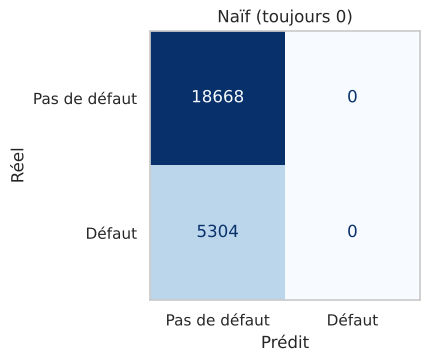

In [5]:
evaluer('Naïf (toujours 0)', DummyClassifier(strategy='most_frequent'))

77,9 % d'accuracy sans détecter un seul défaut (rappel = 0). C'est la démonstration que l'accuracy seule ne suffit pas. Son AUC de 0,5 dit la vérité : il ne sait pas distinguer les clients.

## 3.2 Une règle écrite à la main

L'exploration a montré que le retard de paiement en septembre (`PAY_1`) est le meilleur indice d'un défaut. Une règle simple qu'un banquier pourrait écrire sans ordinateur : **« défaut si le client a au moins un mois de retard en septembre »**. Pour l'AUC, on utilise directement `PAY_1` comme score de risque.

In [5]:
score_regle = X_train['PAY_1'].values
metriques_regle = calculer_metriques(y_train, score_regle, seuil=1)
metriques_regle['Temps (s)'] = 0.0
resultats['Règle PAY_1 ≥ 1'] = metriques_regle
scores_oof['Règle PAY_1 ≥ 1'] = score_regle

for m, v in metriques_regle.items():
    print(f'  {m:<10}: {v:.3f}')

  AUC       : 0.690
  Accuracy  : 0.781
  Précision : 0.505
  Rappel    : 0.520
  F1        : 0.512
  Temps (s) : 0.000


La règle fait déjà bien mieux que le modèle naïf : elle détecte 52 % des défauts, et une alerte sur deux est juste (précision de 50,5 %). Son accuracy (78,1 %) est pourtant presque la même que celle du modèle naïf, alors qu'elle est bien plus utile : encore une preuve que l'accuracy juge mal.

Son AUC de 0,690 est **le niveau à battre**. Une méthode de machine learning qui ferait moins bien qu'une règle d'une ligne n'aurait aucun intérêt.

# 4. Huit méthodes de machine learning

On teste les méthodes de la plus simple à la plus élaborée. Pour chacune : l'idée, une image, les réglages, puis les résultats.

## 4.1 Régression logistique

**L'idée.** Le modèle donne un poids à chaque variable. Il additionne « poids × valeur » pour toutes les variables, puis transforme ce total en probabilité entre 0 et 1 avec la fonction **sigmoïde** (une courbe en S). Pendant l'entraînement, il cherche les poids qui expliquent le mieux les défauts observés.

**Une image.** Une balance : chaque variable pèse plus ou moins lourd du côté « défaut » ou du côté « pas de défaut », et la position de l'aiguille donne la probabilité.

**Ce qu'il faut savoir.**

- C'est un modèle **linéaire** : il suppose que chaque variable augmente ou diminue le risque de façon régulière.
- Il a besoin de variables **à la même échelle**, d'où la standardisation (`StandardScaler`) placée juste avant dans un **pipeline**. Le pipeline enchaîne les deux étapes et recalcule la standardisation sur les seules données d'entraînement de chaque pli, ce qui évite toute fuite d'information.
- Réglage principal : `C`, l'inverse de la **régularisation**. La régularisation empêche les poids de devenir trop grands, ce qui limite le surapprentissage. Petit `C` = modèle très contraint, grand `C` = modèle libre.

Voyons la sigmoïde :

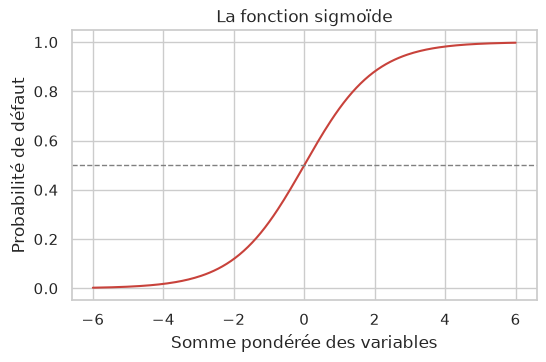

In [6]:
z = np.linspace(-6, 6, 200)
plt.figure(figsize=(6, 3.5))
plt.plot(z, 1 / (1 + np.exp(-z)), color=ROUGE)
plt.axhline(0.5, color='grey', ls='--', lw=1)
plt.xlabel('Somme pondérée des variables')
plt.ylabel('Probabilité de défaut')
plt.title('La fonction sigmoïde')
plt.show()

Plus la somme pondérée est grande, plus la probabilité se rapproche de 1. Une somme de 0 donne exactement 0,5.

**Choisir `C`.** On teste plusieurs valeurs et on compare l'AUC en validation croisée.

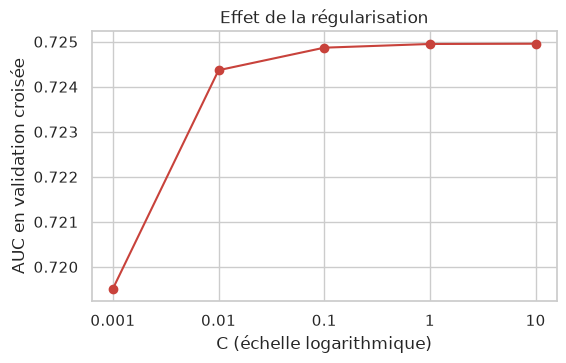

{0.001: 0.7195, 0.01: 0.7244, 0.1: 0.7249, 1: 0.7249, 10: 0.725}


In [7]:
auc_par_C = {}
for C in [0.001, 0.01, 0.1, 1, 10]:
    modele = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))
    score = cross_val_predict(modele, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    auc_par_C[C] = roc_auc_score(y_train, score)

plt.figure(figsize=(6, 3.5))
plt.plot([str(c) for c in auc_par_C], list(auc_par_C.values()), marker='o', color=ROUGE)
plt.xlabel('C (échelle logarithmique)')
plt.ylabel('AUC en validation croisée')
plt.title('Effet de la régularisation')
plt.show()
print({c: round(a, 4) for c, a in auc_par_C.items()})

L'AUC passe de 0,720 avec `C` = 0,001 à 0,724 avec `C` = 0,01, puis ne bouge presque plus (0,725). Avec 24 000 clients pour seulement 26 variables, le modèle a assez d'exemples pour ne pas surapprendre : la régularisation ne change le résultat que si on la rend très forte. On retient `C` = 0,1.

Régression logistique
  AUC       : 0.725
  Accuracy  : 0.810
  Précision : 0.706
  Rappel    : 0.239
  F1        : 0.357
  Temps (s) : 0.286


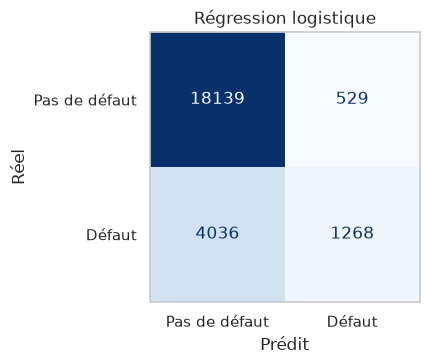

In [9]:
modele_lr = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
evaluer('Régression logistique', modele_lr)

**Lire les poids.** L'avantage de la régression logistique est qu'on peut lire ce qu'elle a appris. Comme les variables sont standardisées, on peut comparer les poids entre eux : un poids positif augmente le risque, un poids négatif le diminue.

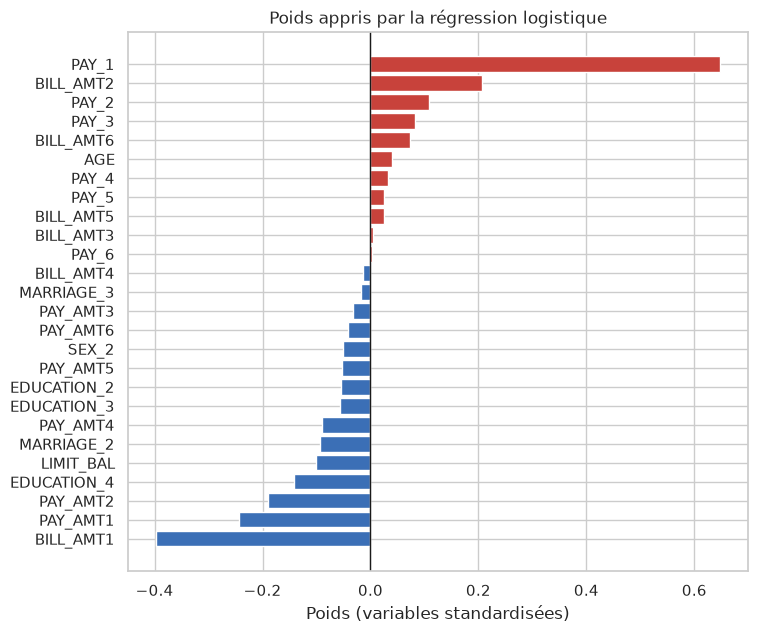

In [10]:
modele_lr.fit(X_train, y_train)
poids = pd.Series(modele_lr[-1].coef_[0], index=X_train.columns).sort_values()

plt.figure(figsize=(8, 7))
plt.barh(poids.index, poids.values, color=[ROUGE if p > 0 else BLEU for p in poids])
plt.axvline(0, color='k', lw=1)
plt.xlabel('Poids (variables standardisées)')
plt.title('Poids appris par la régression logistique')
plt.show()

**Les résultats.** Avec une AUC de 0,725, la régression logistique bat nettement la règle (0,690). Mais au seuil de 0,5, elle ne détecte que 24 % des défauts. Elle est prudente : quand elle annonce un défaut, elle a raison dans 71 % des cas.

**Ce que disent les poids.**

- `PAY_1` a de loin le plus gros poids positif : un retard en septembre augmente fortement le risque. Les statuts des mois précédents vont dans le même sens, avec des poids de plus en plus faibles quand on remonte dans le temps.
- `LIMIT_BAL` et les montants payés (`PAY_AMT1`, `PAY_AMT2`) ont des poids négatifs : un plafond élevé et de gros remboursements protègent du défaut.
- **Un piège à connaître** : `BILL_AMT1` a un fort poids négatif et `BILL_AMT2` un poids positif. Cela ne veut pas dire que la facture de septembre protège et que celle d'août expose. Ces deux variables sont presque identiques (corrélation de 0,95), et le modèle utilise surtout l'écart entre les deux. Quand des variables sont très corrélées, il ne faut pas lire leurs poids un par un.

**La limite.** C'est un modèle linéaire : il suppose que chaque mois de retard ajoute la même quantité de risque. Or l'exploration montrait un risque plat pour `PAY_1` = −2, −1 et 0, puis un saut brutal dès un mois de retard. On verra en 5.1 comment l'aider.

## 4.2 k plus proches voisins (KNN)

**L'idée.** Pour un nouveau client, on cherche les *k* clients de l'entraînement qui lui ressemblent le plus, et on regarde combien d'entre eux ont fait défaut. Si 12 de ses 50 voisins sont en défaut, sa probabilité est de 12/50 = 0,24.

**Une image.** « Dis-moi qui te ressemble, je te dirai qui tu es. »

**Ce qu'il faut savoir.**

- Il n'y a pas vraiment d'apprentissage : le modèle mémorise tous les clients et fait tout le travail au moment de la prédiction, ce qui le rend lent sur de grosses bases.
- Il mesure des **distances** entre clients, donc la standardisation est obligatoire. Sans elle, une différence de 10 000 NT$ de plafond écraserait une différence de 10 ans d'âge.
- Réglage principal : **k**, le nombre de voisins. Petit k : le modèle suit chaque cas particulier et surapprend. Grand k : il fait des moyennes sur beaucoup de clients et devient trop grossier.

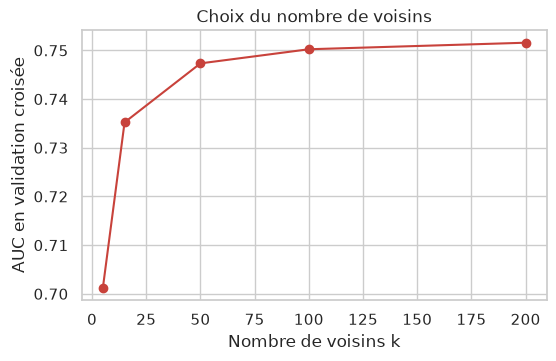

{5: 0.7013, 15: 0.7352, 50: 0.7473, 100: 0.7502, 200: 0.7516}
k retenu : 200


In [11]:
auc_par_k = {}
for k in [5, 15, 50, 100, 200]:
    modele = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    score = cross_val_predict(modele, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    auc_par_k[k] = roc_auc_score(y_train, score)

plt.figure(figsize=(6, 3.5))
plt.plot(list(auc_par_k), list(auc_par_k.values()), marker='o', color=ROUGE)
plt.xlabel('Nombre de voisins k')
plt.ylabel('AUC en validation croisée')
plt.title('Choix du nombre de voisins')
plt.show()
print({k: round(a, 4) for k, a in auc_par_k.items()})
K_CHOISI = max(auc_par_k, key=auc_par_k.get)   # le k qui donne la meilleure AUC
print('k retenu :', K_CHOISI)

L'AUC augmente avec k : 0,701 avec 5 voisins, 0,750 avec 100, 0,752 avec 200. Avec 5 voisins, la prédiction dépend de très peu de clients et change au moindre détail : c'est du surapprentissage. Avec plus de voisins, la moyenne est plus stable. Au-delà de 100 voisins, le gain devient minuscule. Le code retient automatiquement la meilleure valeur testée, k = 200.

KNN (k=200)
  AUC       : 0.752
  Accuracy  : 0.804
  Précision : 0.663
  Rappel    : 0.233
  F1        : 0.345
  Temps (s) : 0.813


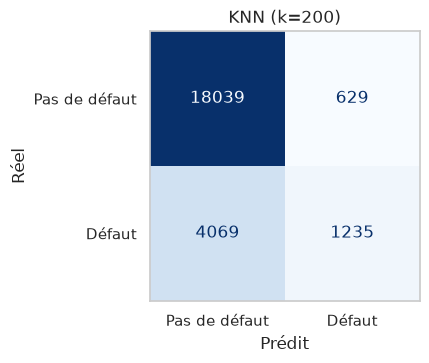

In [12]:
modele_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=K_CHOISI))
evaluer(f'KNN (k={K_CHOISI})', modele_knn)

Le KNN fait mieux que la régression logistique en AUC (0,752 contre 0,725), car il n'impose pas de relation en ligne droite.

Mais son rappel au seuil de 0,5 reste faible (23 %). En faisant la moyenne sur 200 voisins, ses probabilités dépassent rarement 0,5, même pour des clients risqués. C'est un bon exemple où l'AUC et les métriques à seuil racontent deux choses différentes : le classement des clients est correct, c'est le seuil de 0,5 qui est mal adapté. On reviendra sur le choix du seuil en 5.4.

## 4.3 Bayésien naïf (Naive Bayes)

**L'idée.** Le modèle applique la formule de Bayes : il calcule, pour chaque classe, à quel point les valeurs du client sont « typiques » de cette classe, puis combine ces indices pour obtenir une probabilité. La version gaussienne suppose que chaque variable suit une courbe en cloche dans chaque classe.

**Pourquoi « naïf ».** Il suppose que les variables sont **indépendantes** les unes des autres, ce qui est rarement vrai. Ici, c'est même très faux : les six `PAY_k` sont fortement liés entre eux. Le modèle compte alors plusieurs fois le même indice.

**Une image.** Un médecin qui additionne les symptômes un par un sans se demander s'ils ont la même cause.

**Ce qu'il faut savoir.** Il n'y a presque rien à régler et l'entraînement est quasi instantané. C'est un bon modèle de départ quand on a peu de temps ou beaucoup de données.

Bayésien naïf
  AUC       : 0.734
  Accuracy  : 0.565
  Précision : 0.307
  Rappel    : 0.768
  F1        : 0.439
  Temps (s) : 0.208


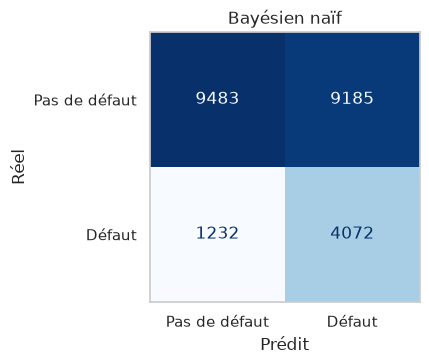

In [13]:
modele_nb = make_pipeline(StandardScaler(), GaussianNB())
evaluer('Bayésien naïf', modele_nb)

Le bayésien naïf se comporte très différemment des autres méthodes. Il détecte 77 % des défauts, mais avec une précision de 31 % (sept alertes sur dix sont fausses) et une accuracy de 57 %, bien pire que le modèle naïf.

C'est la conséquence directe de son hypothèse d'indépendance. Les six `PAY_k` disent à peu près la même chose, mais il les compte comme six indices séparés : il devient beaucoup trop sûr de lui, et beaucoup de clients dépassent le seuil de 0,5.

Pourtant, son AUC (0,734) est meilleure que celle de la régression logistique. Il classe plutôt bien les clients ; ce sont ses probabilités qui sont exagérées. Avec un seuil plus élevé, ses décisions seraient raisonnables.

## 4.4 Machine à vecteurs de support (SVM)

**L'idée.** Le SVM cherche la frontière qui sépare le mieux les deux classes en laissant **la plus grande marge possible** entre la frontière et les clients les plus proches de chaque côté. Avec un **noyau** (ici le noyau RBF, le réglage par défaut), cette frontière peut être courbe.

**Une image.** Tracer la route la plus large possible entre deux villages, sans écraser de maison.

**Ce qu'il faut savoir.**

- Il demande des variables standardisées.
- Il est **lent** : le temps de calcul augmente très vite avec le nombre de clients. Sur nos 24 000 clients, c'est la méthode la plus longue.
- Il ne donne pas directement de probabilité, mais un score (la distance à la frontière). Le seuil naturel est 0. Ça suffit pour calculer l'AUC.
- Réglages principaux : `C` (tolérance aux erreurs) et `gamma` (souplesse de la frontière). On garde les valeurs par défaut.

SVM (noyau RBF)
  AUC       : 0.720
  Accuracy  : 0.819
  Précision : 0.694
  Rappel    : 0.328
  F1        : 0.445
  Temps (s) : 9.030


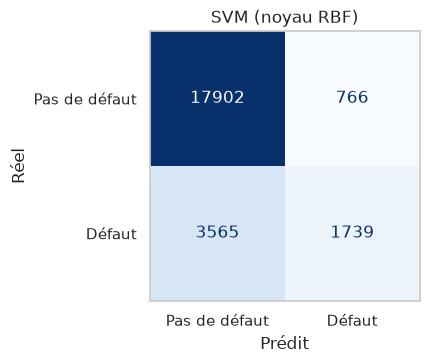

In [14]:
modele_svm = make_pipeline(StandardScaler(), SVC())
evaluer('SVM (noyau RBF)', modele_svm)

Le SVM a l'AUC la plus faible des méthodes testées (0,720), et c'est de loin la plus lente : une trentaine de secondes, contre une fraction de seconde pour la régression logistique. Au seuil naturel de 0, il détecte 33 % des défauts, un peu plus que la régression logistique.

Sur des données en tableau de cette taille, les méthodes à base d'arbres qui suivent font en général mieux, et plus vite.

## 4.5 Arbre de décision

**L'idée.** Le modèle pose une suite de questions de type oui/non (« `PAY_1` > 1 ? », « `LIMIT_BAL` ≤ 50 000 ? »). À chaque étape, il choisit la question qui sépare le mieux les défauts des non-défauts. On descend l'arbre en suivant les réponses jusqu'à une feuille, qui donne la proportion de défauts parmi les clients d'entraînement arrivés là.

**Une image.** Le jeu « Qui est-ce ? ».

**Ce qu'il faut savoir.**

- Très lisible : on peut dessiner l'arbre et l'expliquer à quelqu'un.
- Pas besoin de standardiser : une question du type « plafond > 50 000 ? » ne dépend pas de l'échelle.
- Réglage principal : `max_depth`, la profondeur (le nombre maximum de questions à la suite). Trop profond, il surapprend.

Voici un arbre de profondeur 2 :

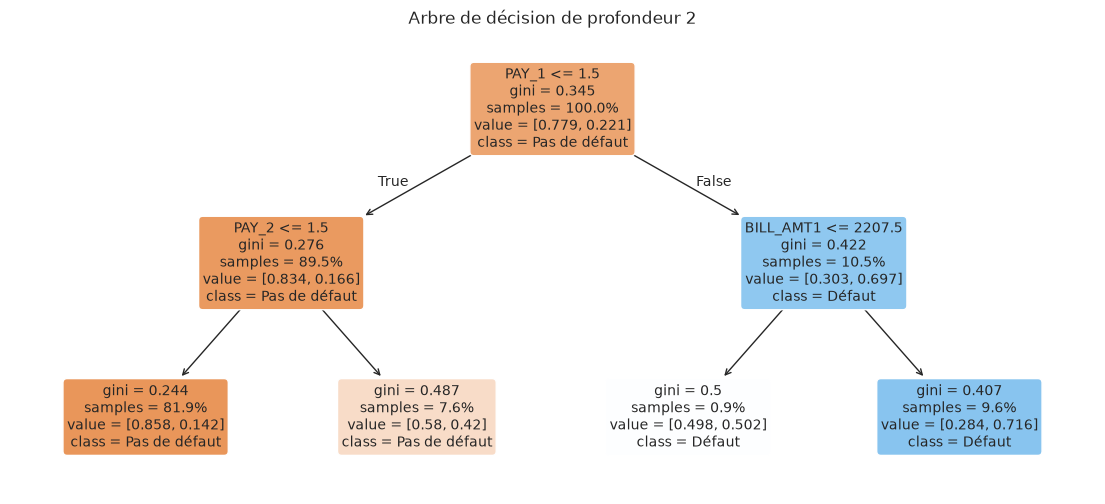

In [15]:
petit_arbre = DecisionTreeClassifier(max_depth=2, random_state=SEED).fit(X_train, y_train)
plt.figure(figsize=(14, 6))
plot_tree(petit_arbre, feature_names=X_train.columns, class_names=['Pas de défaut', 'Défaut'],
          filled=True, rounded=True, proportion=True, fontsize=10)
plt.title('Arbre de décision de profondeur 2')
plt.show()

Dans chaque case : la question, la part des clients qui y arrivent (`samples`), la répartition [pas de défaut, défaut] (`value`) et la classe majoritaire. Le `gini` mesure le mélange des classes dans la case (0 = case pure, 0,5 = moitié-moitié). Orange = majorité sans défaut, bleu = majorité en défaut.

La première question porte sur `PAY_1` : l'arbre a retrouvé tout seul la variable la plus importante. À droite (au moins deux mois de retard en septembre), 70 % des clients sont en défaut.

**Le surapprentissage en image.** On fait varier la profondeur de 1 à 20 et on compare l'AUC sur les données d'entraînement (que le modèle a vues) et en validation croisée (qu'il n'a pas vues).

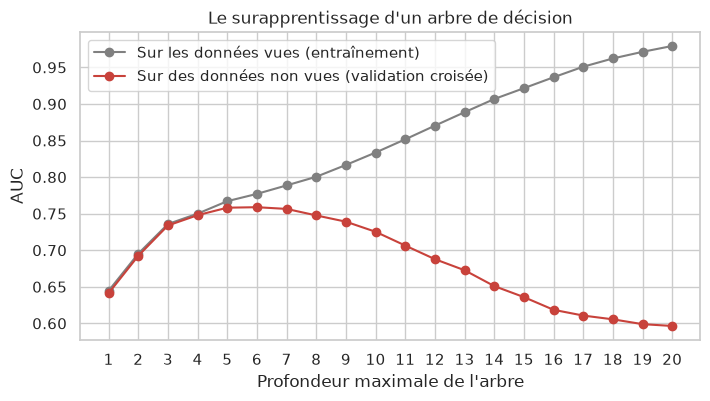

Meilleure profondeur en validation croisée : 6 (AUC 0.759)


In [16]:
profondeurs = range(1, 21)
auc_train, auc_cv = [], []
for p in profondeurs:
    arbre = DecisionTreeClassifier(max_depth=p, random_state=SEED)
    arbre.fit(X_train, y_train)
    auc_train.append(roc_auc_score(y_train, arbre.predict_proba(X_train)[:, 1]))
    score = cross_val_predict(arbre, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    auc_cv.append(roc_auc_score(y_train, score))

plt.figure(figsize=(8, 4))
plt.plot(profondeurs, auc_train, marker='o', color='grey', label='Sur les données vues (entraînement)')
plt.plot(profondeurs, auc_cv, marker='o', color=ROUGE, label='Sur des données non vues (validation croisée)')
plt.xlabel('Profondeur maximale de l\'arbre')
plt.ylabel('AUC')
plt.title('Le surapprentissage d\'un arbre de décision')
plt.xticks(list(profondeurs))
plt.legend()
plt.show()
PROF_CHOISIE = profondeurs[int(np.argmax(auc_cv))]   # la profondeur qui donne la meilleure AUC
print('Meilleure profondeur en validation croisée :', PROF_CHOISIE, f'(AUC {max(auc_cv):.3f})')

C'est le graphique le plus important pour comprendre le surapprentissage.

- La courbe grise (données vues) monte sans arrêt : plus l'arbre est profond, mieux il connaît ses clients d'entraînement. À la profondeur 20, il les connaît presque par cœur (AUC proche de 0,98).
- La courbe rouge (données non vues) monte jusqu'à la profondeur 6 (AUC 0,759), puis redescend jusqu'à 0,60. Au-delà de 6 questions, l'arbre apprend des détails propres à quelques clients, qui ne se retrouvent pas chez les autres.

L'écart qui se creuse entre les deux courbes est la signature du surapprentissage. Le code retient automatiquement la profondeur 6.

Arbre (profondeur 6)
  AUC       : 0.759
  Accuracy  : 0.819
  Précision : 0.664
  Rappel    : 0.366
  F1        : 0.472
  Temps (s) : 0.280


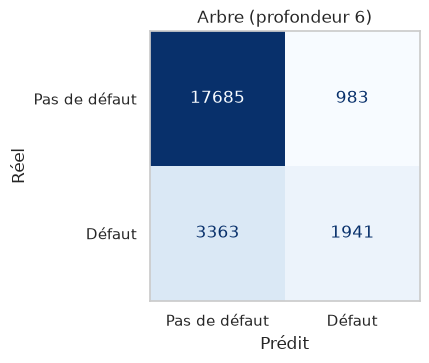

In [17]:
modele_arbre = DecisionTreeClassifier(max_depth=PROF_CHOISIE, random_state=SEED)
evaluer(f'Arbre (profondeur {PROF_CHOISIE})', modele_arbre)

Avec 6 niveaux de questions, l'arbre fait mieux que les quatre méthodes précédentes, en AUC (0,759) comme en F1 (0,472). Il capte naturellement le saut de risque à partir de deux mois de retard, que la régression logistique avait du mal à représenter.

## 4.6 Forêt aléatoire (Random Forest)

**L'idée.** Un seul arbre est instable : changez quelques clients et il peut devenir très différent. La forêt aléatoire entraîne **des centaines d'arbres** et fait la moyenne de leurs réponses. Pour qu'ils ne soient pas tous identiques, chaque arbre :

- apprend sur un tirage au hasard des clients (avec remise) ;
- ne regarde qu'une partie des variables, tirée au hasard, à chaque question.

Les erreurs des arbres se compensent. C'est le principe du **bagging**.

**Une image.** Demander l'avis de 200 experts un peu différents et faire la moyenne, plutôt que de se fier à un seul.

**Ce qu'il faut savoir.**

- Pas de standardisation nécessaire.
- Réglages principaux : `n_estimators` (nombre d'arbres) et `min_samples_leaf` (nombre minimum de clients par feuille, qui limite le surapprentissage de chaque arbre).
- Plus d'arbres ne fait jamais de mal à la qualité, seulement au temps de calcul. Vérifions-le :

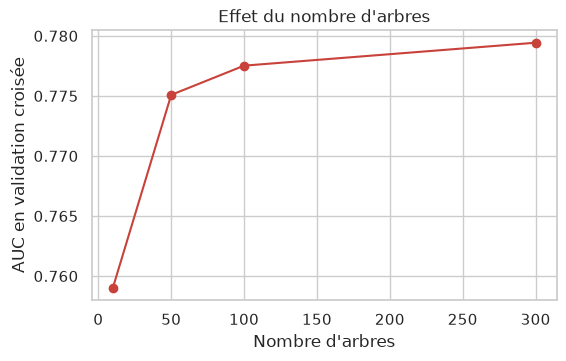

{10: 0.759, 50: 0.7751, 100: 0.7775, 300: 0.7794}


In [18]:
auc_par_n = {}
for n in [10, 50, 100, 300]:
    foret = RandomForestClassifier(n_estimators=n, min_samples_leaf=5, n_jobs=-1, random_state=SEED)
    score = cross_val_predict(foret, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
    auc_par_n[n] = roc_auc_score(y_train, score)

plt.figure(figsize=(6, 3.5))
plt.plot(list(auc_par_n), list(auc_par_n.values()), marker='o', color=ROUGE)
plt.xlabel("Nombre d'arbres")
plt.ylabel('AUC en validation croisée')
plt.title("Effet du nombre d'arbres")
plt.show()
print({n: round(a, 4) for n, a in auc_par_n.items()})

Passer de 10 à 50 arbres fait beaucoup gagner (0,759 à 0,775), puis le gain ralentit : 0,778 avec 100 arbres, 0,779 avec 300. La qualité ne baisse jamais quand on ajoute des arbres ; seul le temps de calcul augmente. On garde 300 arbres.

Forêt aléatoire
  AUC       : 0.779
  Accuracy  : 0.818
  Précision : 0.659
  Rappel    : 0.367
  F1        : 0.471
  Temps (s) : 4.190


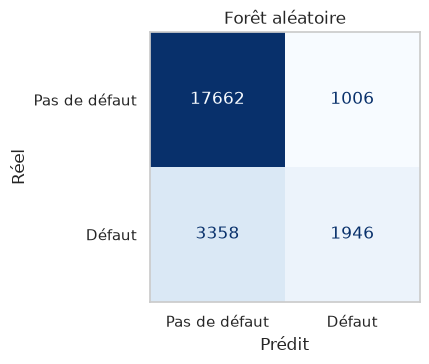

In [19]:
modele_rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED)
evaluer('Forêt aléatoire', modele_rf)

La forêt aléatoire fait nettement mieux qu'un arbre seul en AUC (0,779 contre 0,759). Au seuil de 0,5, les autres métriques sont presque identiques (rappel de 37 %, F1 de 0,47) : la forêt classe mieux les clients, mais prend à peu près les mêmes décisions au seuil de 0,5.

## 4.7 Gradient boosting

**L'idée.** Le gradient boosting combine aussi beaucoup d'arbres, mais **en série** au lieu d'en parallèle. Chaque nouvel arbre est entraîné à corriger les erreurs que font les arbres précédents. Le modèle s'améliore donc étape par étape. C'est le principe du **boosting**.

**Une image.** Un élève qui refait uniquement les exercices qu'il a ratés, encore et encore.

**Ce qu'il faut savoir.**

- C'est souvent la méthode la plus performante sur des données en tableau. Les bibliothèques célèbres XGBoost et LightGBM en sont des variantes. On utilise ici `HistGradientBoostingClassifier` de scikit-learn, qui suit le même principe.
- Réglages principaux : `learning_rate` (la taille de chaque correction), `max_iter` (le nombre d'arbres) et `max_depth` (la profondeur de chaque arbre). On les réglera en partie 5.2.

Gradient boosting
  AUC       : 0.784
  Accuracy  : 0.820
  Précision : 0.676
  Rappel    : 0.360
  F1        : 0.470
  Temps (s) : 0.512


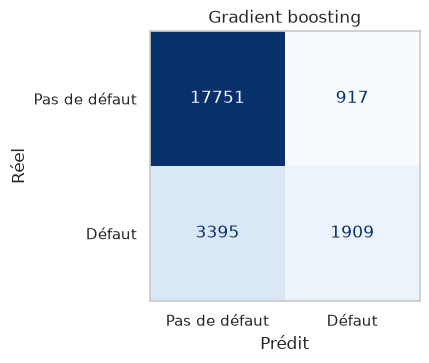

In [20]:
modele_gb = HistGradientBoostingClassifier(random_state=SEED)
evaluer('Gradient boosting', modele_gb)

Le gradient boosting obtient la meilleure AUC (0,784). Il est en plus très rapide : moins d'une seconde pour les 5 entraînements de la validation croisée, contre environ 27 secondes pour la forêt aléatoire.

## 4.8 Réseau de neurones (perceptron multicouche)

**L'idée.** Un réseau de neurones est composé de **couches** de petites unités de calcul (les neurones). Chaque neurone fait une somme pondérée de ce qu'il reçoit, puis applique une fonction simple. La première couche reçoit les variables du client, la dernière donne la probabilité de défaut. Entre les deux, les **couches cachées** construisent des combinaisons de variables de plus en plus élaborées. L'entraînement ajuste tous les poids petit à petit pour réduire les erreurs.

Une régression logistique, c'est en fait un réseau avec un seul neurone. Ajouter des couches permet de capter des relations plus complexes.

**Ce qu'il faut savoir.**

- Standardisation obligatoire.
- Réglages : `hidden_layer_sizes` (le nombre de neurones par couche cachée). Ici, (32, 16) signifie deux couches cachées de 32 puis 16 neurones. `alpha` règle la régularisation.
- `early_stopping=True` arrête l'entraînement quand le modèle cesse de progresser sur une petite partie des données mise de côté, pour éviter le surapprentissage.
- Les réseaux de neurones brillent sur les images, le son ou le texte. Sur un petit tableau comme le nôtre, ils font rarement mieux que le gradient boosting.

Réseau de neurones
  AUC       : 0.766
  Accuracy  : 0.819
  Précision : 0.665
  Rappel    : 0.364
  F1        : 0.471
  Temps (s) : 0.937


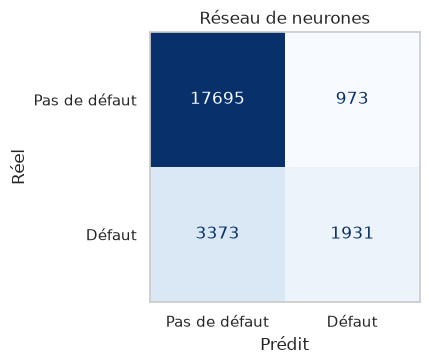

In [21]:
modele_mlp = make_pipeline(StandardScaler(),
                           MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3, early_stopping=True,
                                         max_iter=300, random_state=SEED))
evaluer('Réseau de neurones', modele_mlp)

Le réseau de neurones se place entre l'arbre et la forêt (AUC 0,766). Il fait mieux que la régression logistique, qui n'est qu'un réseau à un seul neurone : les couches cachées lui permettent de capter des relations non linéaires. Mais il ne rattrape pas les meilleures méthodes à base d'arbres. Ses résultats dépendent aussi beaucoup de ses réglages (nombre de couches, de neurones, régularisation), qu'on n'a pas cherché à optimiser.

## 4.9 Comparaison des huit méthodes

On rassemble les résultats dans un tableau trié par AUC.

,AUC,Accuracy,Précision,Rappel,F1,Temps (s)
Gradient boosting,0.784,0.820,0.676,0.360,0.470,0.512
Forêt aléatoire,0.779,0.818,0.659,0.367,0.471,4.190
Réseau de neurones,0.766,0.819,0.665,0.364,0.471,0.937
Arbre (profondeur 6),0.759,0.819,0.664,0.366,0.472,0.280
KNN (k=200),0.752,0.804,0.663,0.233,0.345,0.813
Bayésien naïf,0.734,0.565,0.307,0.768,0.439,0.208
Régression logistique,0.725,0.810,0.706,0.239,0.357,0.286
SVM (noyau RBF),0.720,0.819,0.694,0.328,0.445,9.030
Règle PAY_1 ≥ 1,0.690,0.781,0.505,0.520,0.512,0.000


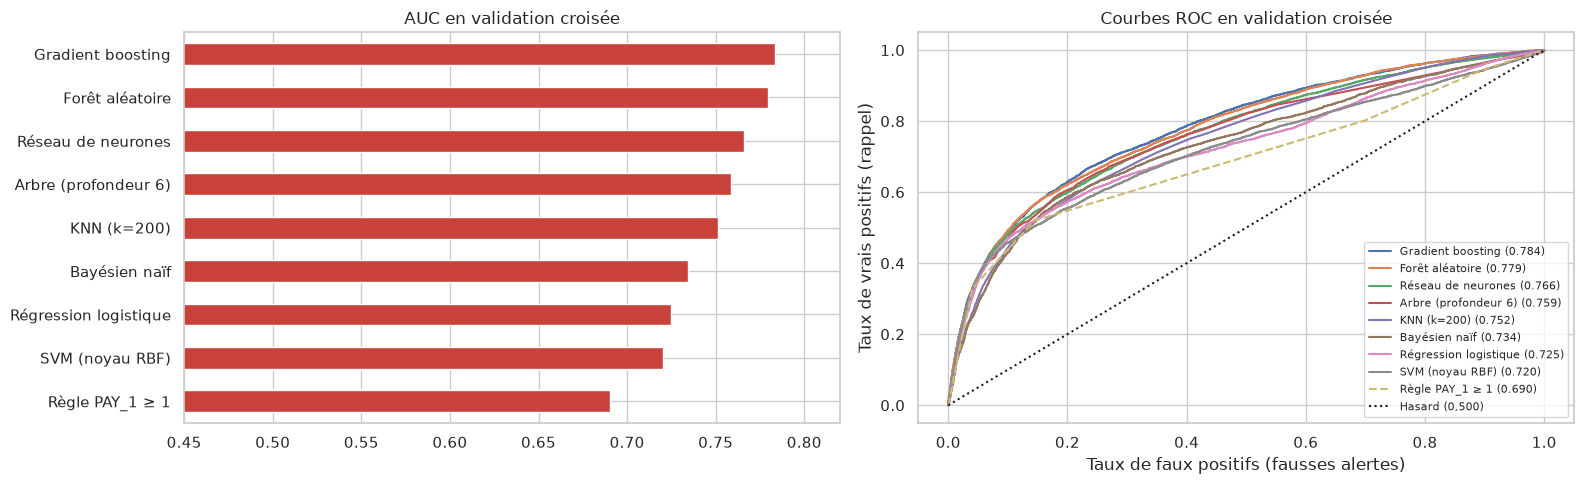

In [22]:
comparaison = pd.DataFrame(resultats).T.sort_values('AUC', ascending=False)
display(comparaison.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
comparaison['AUC'].sort_values().plot(kind='barh', color=ROUGE, ax=axes[0])
axes[0].set_xlim(0.45, 0.82)
axes[0].set_title('AUC en validation croisée')

for nom in comparaison.index:
    if nom.startswith('Naïf'):
        continue
    fpr, tpr, _ = roc_curve(y_train, scores_oof[nom])
    style = '--' if nom.startswith('Règle') else '-'
    axes[1].plot(fpr, tpr, style, label=f'{nom} ({resultats[nom]["AUC"]:.3f})')
axes[1].plot([0, 1], [0, 1], 'k:', label='Hasard (0,500)')
axes[1].set(xlabel='Taux de faux positifs (fausses alertes)', ylabel='Taux de vrais positifs (rappel)',
            title='Courbes ROC en validation croisée')
axes[1].legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

**Comment lire les courbes ROC.** Chaque courbe montre ce qu'on obtient en faisant varier le seuil de décision : en allant vers la droite, on abaisse le seuil, on détecte plus de défauts (on monte) mais on déclenche plus de fausses alertes. Plus une courbe est proche du coin en haut à gauche, meilleur est le modèle. L'AUC est l'aire sous cette courbe.

**Ce que montre la comparaison.**

- **Les méthodes à base d'arbres sont en tête** : gradient boosting (0,784) et forêt aléatoire (0,779). Le réseau de neurones (0,766) et l'arbre seul (0,759) suivent.
- **Les méthodes linéaires ou fondées sur des distances sont derrière** : KNN (0,752), bayésien naïf (0,734), régression logistique (0,725) et SVM (0,720).
- **Toutes battent la règle `PAY_1 ≥ 1`** (0,690). Mais l'écart entre la meilleure et la moins bonne méthode (0,06) est bien plus petit que l'écart entre la règle et le modèle naïf (0,19). L'essentiel de l'information tient dans `PAY_1`, qu'une règle d'une ligne exploite déjà.
- **Au seuil de 0,5, aucune méthode ne détecte plus de 37 % des défauts**, sauf le bayésien naïf, qui le paie par une précision très faible.

Les courbes ROC sont presque confondues à gauche : pour repérer les clients les plus risqués, toutes les méthodes sont d'accord. Elles se séparent au milieu, sur les clients intermédiaires, plus difficiles à classer.

Le gradient boosting est à la fois le meilleur et le plus rapide. C'est lui qu'on cherche à améliorer dans la partie 5. On suivra aussi la régression logistique, pour voir si une méthode simple peut combler une partie de son retard.

# 5. Améliorer les modèles

Il existe quatre grandes façons d'améliorer un modèle. On les essaie une par une.

## 5.1 Créer de nouvelles variables (*feature engineering*)

Un modèle ne voit que les colonnes qu'on lui donne. Parfois, une information utile est cachée dans une combinaison de colonnes. En s'appuyant sur ce que l'exploration a montré, on crée cinq nouvelles variables :

| Nouvelle variable | Calcul | Pourquoi |
|---|---|---|
| `NB_MOIS_RETARD` | Nombre de mois avec au moins un mois de retard, sur les 6 | Un client souvent en retard est plus risqué qu'un client en retard une seule fois |
| `RETARD_MAX` | Le plus grand retard sur les 6 mois | Résume la gravité de l'historique |
| `TAUX_UTILISATION` | Facture de septembre / plafond | Un client proche de son plafond a peu de marge |
| `PART_REMBOURSEE` | Total payé / total facturé sur 6 mois | L'exploration montrait que les défaillants paient moins, pour des factures similaires |
| `EVOLUTION_DETTE` | (Facture de septembre − facture d'avril) / plafond | La dette du client grossit-elle ? |

On écrit une fonction qu'on applique séparément à l'entraînement et au test. Elle ne fait que des calculs ligne par ligne, sans rien apprendre des données, donc elle ne crée aucune fuite d'information.

In [23]:
def ajouter_variables(X):
    X = X.copy()
    statuts = [f'PAY_{k}' for k in range(1, 7)]
    factures = [f'BILL_AMT{k}' for k in range(1, 7)]
    paiements = [f'PAY_AMT{k}' for k in range(1, 7)]

    X['NB_MOIS_RETARD'] = (X[statuts] >= 1).sum(axis=1)
    X['RETARD_MAX'] = X[statuts].max(axis=1).clip(lower=0)
    X['TAUX_UTILISATION'] = X['BILL_AMT1'] / X['LIMIT_BAL']

    total_facture = X[factures].sum(axis=1)
    total_paye = X[paiements].sum(axis=1)
    # Si le client n'a rien eu à payer, on considère qu'il a tout remboursé (part = 1)
    part = np.where(total_facture > 0, total_paye / total_facture.where(total_facture > 0), 1.0)
    X['PART_REMBOURSEE'] = np.clip(part, 0, 2)   # on borne les valeurs extrêmes

    X['EVOLUTION_DETTE'] = (X['BILL_AMT1'] - X['BILL_AMT6']) / X['LIMIT_BAL']
    return X


X_train_plus = ajouter_variables(X_train)
X_test_plus = ajouter_variables(X_test)
nouvelles = ['NB_MOIS_RETARD', 'RETARD_MAX', 'TAUX_UTILISATION', 'PART_REMBOURSEE', 'EVOLUTION_DETTE']
X_train_plus[nouvelles].describe().round(2)

,NB_MOIS_RETARD,RETARD_MAX,TAUX_UTILISATION,PART_REMBOURSEE,EVOLUTION_DETTE
count,23972.00,23972.00,23972.00,23972.00,23972.00
mean,0.83,0.68,0.43,0.38,0.11
std,1.55,1.07,0.41,0.46,0.31
min,0.00,0.00,-0.62,0.00,-1.83
25%,0.00,0.00,0.02,0.04,-0.03
50%,0.00,0.00,0.32,0.11,0.01
75%,1.00,2.00,0.83,0.71,0.18
max,6.00,8.00,6.46,2.00,5.31


Est-ce que ces variables sont liées au défaut ? On regarde le taux de défaut selon le nombre de mois en retard, et la distribution de la part remboursée dans chaque classe.

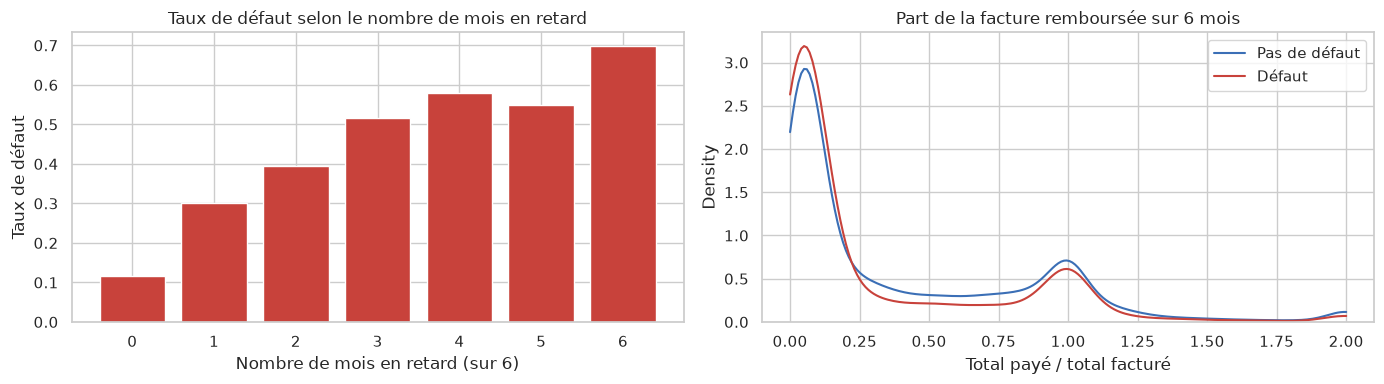

NB_MOIS_RETARD
0    0.116
1    0.300
2    0.394
3    0.517
4    0.581
5    0.549
6    0.698
Name: DEFAULT, dtype: float64


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

taux = y_train.groupby(X_train_plus['NB_MOIS_RETARD']).mean()
axes[0].bar(taux.index.astype(str), taux.values, color=ROUGE)
axes[0].set(xlabel='Nombre de mois en retard (sur 6)', ylabel='Taux de défaut',
            title='Taux de défaut selon le nombre de mois en retard')

for classe, couleur, nom in [(0, BLEU, 'Pas de défaut'), (1, ROUGE, 'Défaut')]:
    sns.kdeplot(X_train_plus.loc[y_train == classe, 'PART_REMBOURSEE'], color=couleur, label=nom,
                ax=axes[1], clip=(0, 2))
axes[1].set(title='Part de la facture remboursée sur 6 mois', xlabel='Total payé / total facturé')
axes[1].legend()
plt.tight_layout()
plt.show()
print(taux.round(3))

- **Nombre de mois en retard** : le taux de défaut monte presque régulièrement, de 12 % pour les clients jamais en retard à 30 % avec un mois, 52 % avec trois mois et 70 % pour les clients en retard les six mois. Cette variable résume l'historique en une seule colonne, beaucoup plus parlante que les six `PAY_k` séparés.
- **Part remboursée** : les deux courbes sont très proches. Les clients en défaut sont un peu plus nombreux près de 0 (ils remboursent une petite part de leur facture) et les autres un peu plus nombreux autour de 1 (ils remboursent tout). La variable porte de l'information, mais moins que prévu.

Toutes les idées de variables ne se valent pas. C'est le modèle qui dira lesquelles servent vraiment.

On réévalue maintenant la régression logistique et le gradient boosting avec ces variables en plus.

In [25]:
evaluer('Régression logistique + variables', modele_lr, X=X_train_plus, afficher=False)
evaluer('Gradient boosting + variables', modele_gb, X=X_train_plus, afficher=False)

pd.DataFrame(resultats).T.loc[['Régression logistique', 'Régression logistique + variables',
                               'Gradient boosting', 'Gradient boosting + variables'],
                              ['AUC', 'Rappel', 'F1']].round(3)

,AUC,Rappel,F1
Régression logistique,0.725,0.239,0.357
Régression logistique + variables,0.761,0.300,0.410
Gradient boosting,0.784,0.360,0.470
Gradient boosting + variables,0.786,0.361,0.471


- **La régression logistique gagne près de 4 points d'AUC** (0,725 à 0,761) et son rappel passe de 24 % à 30 %. Les nouvelles variables lui apportent ce qu'elle ne savait pas construire seule : `NB_MOIS_RETARD` croît régulièrement avec le risque, exactement le type de relation qu'un modèle linéaire sait utiliser.
- **Le gradient boosting ne gagne presque rien** (0,784 à 0,786). Avec ses dizaines d'arbres, il avait déjà trouvé ces combinaisons tout seul.

À retenir : créer des variables aide surtout les modèles simples. Pour les modèles puissants, cela rend surtout le modèle plus facile à expliquer, comme on le verra en partie 7.

## 5.2 Régler les hyperparamètres

Jusqu'ici, le gradient boosting utilisait ses réglages par défaut. Pour trouver de meilleurs réglages, deux approches existent :

- **la recherche en grille** (`GridSearchCV`) : on teste toutes les combinaisons d'une liste de valeurs. Avec 5 réglages à 4 valeurs, cela fait déjà 4⁵ = 1 024 combinaisons, chacune évaluée 5 fois ;
- **la recherche aléatoire** (`RandomizedSearchCV`) : on tire au hasard un nombre fixé de combinaisons (ici 20). C'est beaucoup plus rapide, et en pratique on trouve presque aussi bien.

Chaque combinaison est évaluée par validation croisée sur l'entraînement. Le test reste intact.

Les réglages testés :

- `learning_rate` : la taille de chaque correction. Petit = apprentissage lent mais prudent ;
- `max_iter` : le nombre d'arbres ;
- `max_depth` : la profondeur de chaque arbre ;
- `min_samples_leaf` : le nombre minimum de clients par feuille ;
- `l2_regularization` : une pénalité qui freine les corrections trop fortes.

In [26]:
reglages_possibles = {
    'learning_rate': [0.02, 0.05, 0.1, 0.2],
    'max_iter': [100, 200, 400],
    'max_depth': [3, 5, 8, None],
    'min_samples_leaf': [20, 50, 100, 200],
    'l2_regularization': [0.0, 0.5, 2.0],
}
recherche = RandomizedSearchCV(HistGradientBoostingClassifier(random_state=SEED), reglages_possibles,
                               n_iter=20, scoring='roc_auc', cv=cv, random_state=SEED, n_jobs=-1)
recherche.fit(X_train_plus, y_train)

print('Meilleurs réglages :', recherche.best_params_)
print(f'AUC en validation croisée : {recherche.best_score_:.4f}')

essais = pd.DataFrame(recherche.cv_results_)
essais = essais[[c for c in essais.columns if c.startswith('param_')] + ['mean_test_score']]
essais.columns = [c.replace('param_', '') for c in essais.columns[:-1]] + ['AUC']
essais.sort_values('AUC', ascending=False).head(8).round(4)

Meilleurs réglages : {'min_samples_leaf': 200, 'max_iter': 200, 'max_depth': 3, 'learning_rate': 0.05, 'l2_regularization': 0.0}
AUC en validation croisée : 0.7884


,min_samples_leaf,max_iter,max_depth,learning_rate,l2_regularization,AUC
17,200,200,3,0.05,0.0,0.7884
10,100,100,None,0.05,2.0,0.7883
11,200,100,5,0.05,2.0,0.7882
4,100,200,5,0.02,2.0,0.7882
8,100,400,8,0.05,0.0,0.7881
16,50,100,8,0.05,0.5,0.7880
1,100,400,5,0.10,0.0,0.7880
6,200,200,5,0.05,0.5,0.7880


In [27]:
gb_regle = HistGradientBoostingClassifier(**recherche.best_params_, random_state=SEED)
evaluer('Gradient boosting réglé + variables', gb_regle, X=X_train_plus, afficher=False)
pd.DataFrame(resultats).T.loc[['Gradient boosting', 'Gradient boosting + variables',
                               'Gradient boosting réglé + variables'], ['AUC', 'Rappel', 'F1']].round(3)

,AUC,Rappel,F1
Gradient boosting,0.784,0.360,0.470
Gradient boosting + variables,0.786,0.361,0.471
Gradient boosting réglé + variables,0.788,0.359,0.471


Le meilleur réglage trouvé est un modèle prudent : 200 arbres peu profonds (profondeur 3), un apprentissage modéré (`learning_rate` = 0,05) et au moins 200 clients par feuille, ce qui l'empêche d'apprendre des cas particuliers.

L'AUC passe de 0,786 à 0,788 : un gain très faible. Le tableau des essais montre pourquoi : les huit meilleures combinaisons sont toutes entre 0,7880 et 0,7884, alors qu'elles sont très différentes (profondeur 3 ou sans limite, 100 ou 400 arbres). Beaucoup de réglages mènent au même résultat. Les réglages par défaut étaient déjà bons, et la limite vient des données elles-mêmes : aucun réglage ne permet de prédire ce que les variables ne contiennent pas.

## 5.3 Combiner plusieurs modèles

Des modèles différents font des erreurs différentes. En faisant la **moyenne de leurs probabilités**, on peut espérer que les erreurs se compensent. C'est le **vote souple** (`VotingClassifier` avec `voting='soft'`).

On combine trois modèles de familles différentes : la régression logistique (linéaire), la forêt aléatoire (bagging) et le gradient boosting réglé (boosting).

In [28]:
vote = VotingClassifier(
    estimators=[('logistique', modele_lr), ('foret', modele_rf), ('boosting', gb_regle)],
    voting='soft', n_jobs=-1)
evaluer('Vote (logistique + forêt + boosting)', vote, X=X_train_plus, afficher=False)
pd.DataFrame(resultats).T.loc[['Gradient boosting réglé + variables',
                               'Vote (logistique + forêt + boosting)'], ['AUC', 'Rappel', 'F1', 'Temps (s)']].round(3)

,AUC,Rappel,F1,Temps (s)
Gradient boosting réglé + variables,0.788,0.359,0.471,0.695
Vote (logistique + forêt + boosting),0.788,0.369,0.476,10.402


Le vote atteint la même AUC que le gradient boosting seul (0,788), avec un rappel et un F1 à peine meilleurs (37 % contre 36 %, 0,476 contre 0,471). Il est en revanche plus de 20 fois plus long (environ 30 secondes contre 1,3), à cause de la forêt aléatoire.

Ici, combiner n'en vaut pas la peine. Les trois modèles exploitent surtout la même information (le retard de paiement) et se trompent sans doute sur les mêmes clients, donc leurs erreurs ne se compensent pas. On garde le gradient boosting seul, plus simple et plus rapide.

## 5.4 Mieux détecter les défauts : le choix du seuil

Tous les modèles précédents ont un rappel faible au seuil de 0,5 : ils ratent la majorité des défauts. La raison est simple : avec 78 % de clients sans défaut, un modèle prudent a intérêt à répondre « pas de défaut » dans le doute.

Pour une banque, rater un défaut coûte souvent plus cher qu'une fausse alerte. Deux solutions :

1. **pondérer les classes** à l'entraînement (`class_weight='balanced'`) : chaque erreur sur un client en défaut compte environ 3,5 fois plus ;
2. **abaisser le seuil de décision** : on garde le même modèle, mais on déclare « défaut » dès que la probabilité dépasse, par exemple, 0,25 au lieu de 0,5.

La deuxième solution est la plus souple : elle marche avec n'importe quel modèle et on peut ajuster le seuil sans réentraîner. On l'applique au gradient boosting réglé.

Le graphique ci-dessous montre la précision, le rappel et le F1 pour tous les seuils possibles, à partir des probabilités obtenues en validation croisée. On choisit le seuil qui **maximise le F1**, le meilleur compromis entre précision et rappel quand on n'a pas d'autre critère.

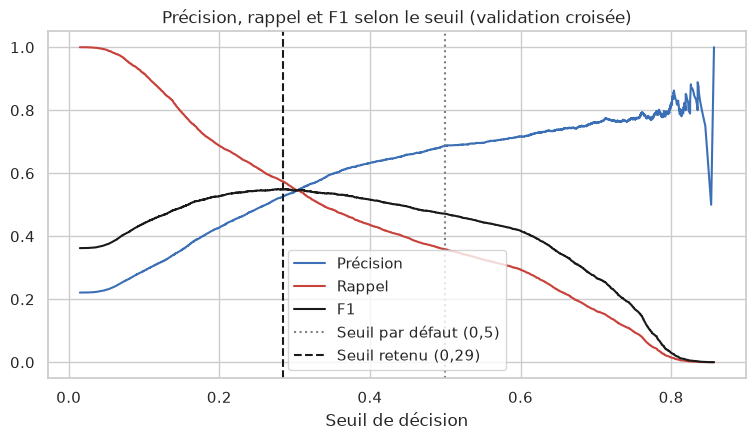

,AUC,Accuracy,Précision,Rappel,F1
"Seuil 0,5",0.788,0.822,0.687,0.359,0.471
"Seuil 0,29",0.788,0.792,0.527,0.574,0.550


In [29]:
proba_oof = scores_oof['Gradient boosting réglé + variables']
precision, rappel, seuils = precision_recall_curve(y_train, proba_oof)
f1 = 2 * precision[:-1] * rappel[:-1] / (precision[:-1] + rappel[:-1] + 1e-12)
SEUIL = seuils[np.argmax(f1)]

plt.figure(figsize=(9, 4.5))
plt.plot(seuils, precision[:-1], color=BLEU, label='Précision')
plt.plot(seuils, rappel[:-1], color=ROUGE, label='Rappel')
plt.plot(seuils, f1, color='k', label='F1')
plt.axvline(0.5, color='grey', ls=':', label='Seuil par défaut (0,5)')
plt.axvline(SEUIL, color='k', ls='--', label=f'Seuil retenu ({SEUIL:.2f})'.replace('.', ','))
plt.xlabel('Seuil de décision')
plt.title('Précision, rappel et F1 selon le seuil (validation croisée)')
plt.legend()
plt.show()

comparaison_seuil = pd.DataFrame({
    'Seuil 0,5': calculer_metriques(y_train, proba_oof, 0.5),
    f'Seuil {SEUIL:.2f}'.replace('.', ','): calculer_metriques(y_train, proba_oof, SEUIL),
}).T
comparaison_seuil.round(3)

En abaissant le seuil de 0,5 à 0,29 :

- le rappel passe de 36 % à 57 % : on détecte beaucoup plus de défauts ;
- la précision baisse de 69 % à 53 % : un peu plus d'une alerte sur deux reste juste ;
- le F1 passe de 0,47 à 0,55 ;
- l'AUC ne bouge pas : le modèle et son classement des clients sont exactement les mêmes. Seule la décision change.

Le seuil est choisi à partir des prédictions de validation croisée, jamais à partir du test. Dans un vrai projet bancaire, on le fixerait plutôt à partir des coûts : combien coûte un défaut raté, combien coûte une fausse alerte.

Pour comparaison, la pondération des classes donne un résultat du même ordre :

In [30]:
gb_pondere = HistGradientBoostingClassifier(**recherche.best_params_, class_weight='balanced',
                                            random_state=SEED)
evaluer('Gradient boosting réglé + variables + pondération', gb_pondere, X=X_train_plus, afficher=False)
pd.DataFrame(resultats).T.loc[['Gradient boosting réglé + variables + pondération']].round(3)

,AUC,Accuracy,Précision,Rappel,F1,Temps (s)
Gradient boosting réglé + variables + pondération,0.787,0.75,0.454,0.65,0.535,1.696


La pondération va encore plus loin vers le rappel (65 %), au prix d'une précision plus faible (45 %), pour un F1 de 0,535. Les deux approches mènent au même type de compromis. On garde le choix du seuil : il donne un F1 légèrement meilleur (0,550) et on peut l'ajuster sans réentraîner le modèle.

## 5.5 Faut-il plus de données ?

Une **courbe d'apprentissage** montre comment le score évolue quand on entraîne le modèle sur de plus en plus de clients. Si la courbe monte encore à droite, collecter plus de données aiderait. Si elle est plate, le modèle a déjà tiré ce qu'il pouvait de ce type de données.

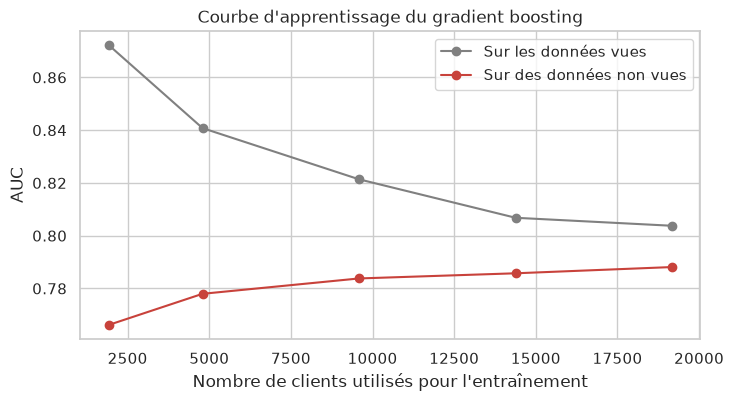

 clients  AUC vues  AUC non vues
    1917     0.872         0.766
    4794     0.841         0.778
    9588     0.821         0.784
   14382     0.807         0.786
   19177     0.804         0.788


In [31]:
tailles, scores_train_lc, scores_cv_lc = learning_curve(
    gb_regle, X_train_plus, y_train, train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0],
    cv=cv, scoring='roc_auc', n_jobs=-1)

plt.figure(figsize=(8, 4))
plt.plot(tailles, scores_train_lc.mean(axis=1), marker='o', color='grey', label='Sur les données vues')
plt.plot(tailles, scores_cv_lc.mean(axis=1), marker='o', color=ROUGE, label='Sur des données non vues')
plt.xlabel("Nombre de clients utilisés pour l'entraînement")
plt.ylabel('AUC')
plt.title("Courbe d'apprentissage du gradient boosting")
plt.legend()
plt.show()
print(pd.DataFrame({'clients': tailles, 'AUC vues': scores_train_lc.mean(axis=1),
                    'AUC non vues': scores_cv_lc.mean(axis=1)}).round(3).to_string(index=False))

- Avec 1 900 clients, l'écart entre les deux courbes est grand (0,872 sur les données vues, 0,766 sur les données non vues) : faute d'exemples, le modèle surapprend.
- En ajoutant des clients, les deux courbes se rapprochent : le modèle généralise de mieux en mieux.
- La courbe rouge monte encore un peu entre 14 000 et 19 000 clients (0,786 à 0,788), mais elle s'aplatit.

Plus de clients du même type n'apporterait donc qu'un gain faible. Pour vraiment progresser, il faudrait **d'autres informations** sur les clients (revenus, autres crédits, ancienneté), pas davantage de clients.

# 6. Évaluation finale sur le jeu de test

On a fait tous nos choix sur l'entraînement : les variables, la méthode, les réglages et le seuil. Le modèle final est :

- **gradient boosting** avec les réglages trouvés en 5.2 ;
- entraîné avec les **variables ajoutées** en 5.1 ;
- avec le **seuil de décision** choisi en 5.4.

On l'entraîne sur tout le jeu d'entraînement, puis on l'évalue **une seule fois** sur les 5 993 clients du test.

,AUC,Accuracy,Précision,Rappel,F1
Validation croisée (entraînement),0.788,0.792,0.527,0.574,0.550
Test,0.776,0.787,0.517,0.561,0.538
Règle PAY_1 ≥ 1 sur le test,0.687,0.778,0.498,0.503,0.501


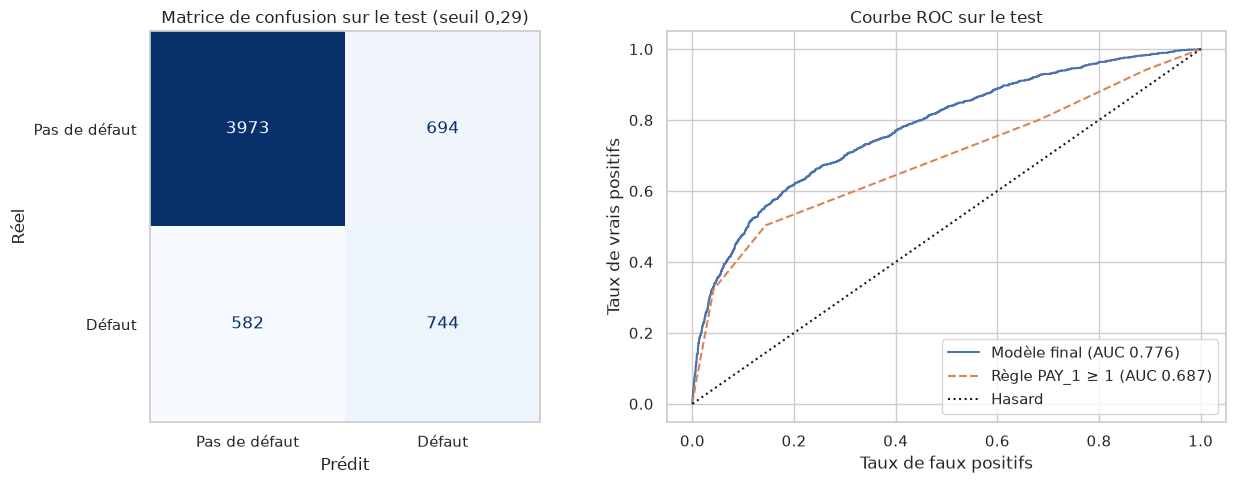

In [32]:
modele_final = HistGradientBoostingClassifier(**recherche.best_params_, random_state=SEED)
modele_final.fit(X_train_plus, y_train)
proba_test = modele_final.predict_proba(X_test_plus)[:, 1]

final = pd.DataFrame({
    'Validation croisée (entraînement)': calculer_metriques(y_train, proba_oof, SEUIL),
    'Test': calculer_metriques(y_test, proba_test, SEUIL),
    'Règle PAY_1 ≥ 1 sur le test': calculer_metriques(y_test, X_test['PAY_1'].values, 1),
}).T
display(final.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, (proba_test >= SEUIL).astype(int),
                                        display_labels=['Pas de défaut', 'Défaut'],
                                        cmap='Blues', colorbar=False, ax=axes[0])
axes[0].set(title=f'Matrice de confusion sur le test (seuil {SEUIL:.2f})'.replace('.', ','),
            xlabel='Prédit', ylabel='Réel')
axes[0].grid(False)

for nom, score, style in [('Modèle final', proba_test, '-'),
                          ('Règle PAY_1 ≥ 1', X_test['PAY_1'].values, '--')]:
    fpr, tpr, _ = roc_curve(y_test, score)
    axes[1].plot(fpr, tpr, style, label=f'{nom} (AUC {roc_auc_score(y_test, score):.3f})')
axes[1].plot([0, 1], [0, 1], 'k:', label='Hasard')
axes[1].set(title='Courbe ROC sur le test', xlabel='Taux de faux positifs', ylabel='Taux de vrais positifs')
axes[1].legend()
plt.tight_layout()
plt.show()

**Le modèle tient ses promesses.** Les scores sur le test sont très proches de ceux de la validation croisée : AUC de 0,776 contre 0,788, rappel de 56 % contre 57 %, F1 de 0,538 contre 0,550. Un léger recul est normal, puisque le modèle et le seuil ont été choisis pour bien marcher sur l'entraînement. Il reste faible : le modèle se comporte de la même façon face à de nouveaux clients.

**Lecture de la matrice de confusion**, sur les 5 993 clients du test :

- 1 326 clients sont réellement en défaut. Le modèle en détecte **744** (56 %) et en rate 582.
- 4 667 clients ne font pas défaut. Le modèle en signale 694 à tort (15 %).
- Au total, il déclenche 1 438 alertes, dont 52 % sont justes.

**Par rapport à la règle `PAY_1 ≥ 1`**, l'AUC passe de 0,687 à 0,776. À précision presque égale (52 % contre 50 %), le modèle détecte 56 % des défauts au lieu de 50 %. Sur la courbe ROC, les deux sont proches pour les clients les plus risqués (à gauche), puis le modèle prend nettement l'avantage.

# 7. Comprendre ce que le modèle a appris

Un gradient boosting de plusieurs centaines d'arbres ne se lit pas comme un arbre seul. Deux outils permettent quand même de comprendre ce qu'il fait.

## 7.1 Quelles variables comptent ?

**L'importance par permutation** : on mélange au hasard les valeurs d'une variable (ce qui détruit l'information qu'elle porte) et on mesure de combien l'AUC baisse sur le test. Grosse baisse = variable importante. On répète 5 fois par variable.

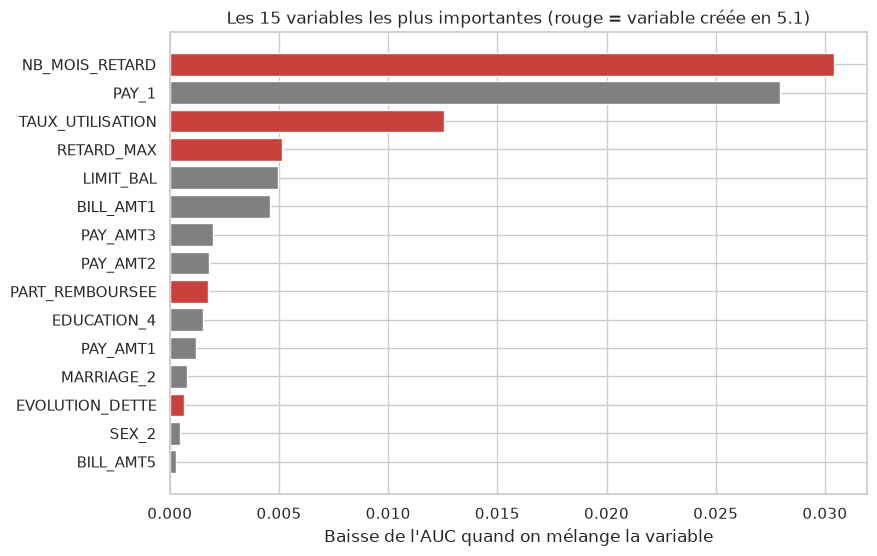

NB_MOIS_RETARD      0.0304
PAY_1               0.0279
TAUX_UTILISATION    0.0125
RETARD_MAX          0.0051
LIMIT_BAL           0.0049
BILL_AMT1           0.0046
PAY_AMT3            0.0020
PAY_AMT2            0.0018
dtype: float64


In [33]:
perm = permutation_importance(modele_final, X_test_plus, y_test, scoring='roc_auc',
                              n_repeats=5, random_state=SEED, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_test_plus.columns).sort_values()
top = importance.tail(15)

plt.figure(figsize=(9, 6))
plt.barh(top.index, top.values, color=[ROUGE if c in nouvelles else 'grey' for c in top.index])
plt.xlabel("Baisse de l'AUC quand on mélange la variable")
plt.title('Les 15 variables les plus importantes (rouge = variable créée en 5.1)')
plt.show()
print(importance.sort_values(ascending=False).head(8).round(4))

- **Deux variables dominent** : `NB_MOIS_RETARD`, créée en 5.1, arrive en première position, juste devant `PAY_1`.
- Viennent ensuite `TAUX_UTILISATION` (une autre variable créée), `RETARD_MAX`, le plafond `LIMIT_BAL` et la facture de septembre `BILL_AMT1`.
- Trois des quatre premières variables sont des variables qu'on a construites. Elles n'ont presque pas changé l'AUC du boosting, mais le modèle s'en sert parce qu'elles résument en une colonne ce qu'il devait autrement combiner à partir de plusieurs.
- Les variables démographiques (`EDUCATION_4`, `MARRIAGE_2`, `SEX_2`) n'apparaissent qu'en bas du classement, avec des valeurs très faibles. Une fois le comportement de paiement connu, elles n'apportent presque rien.

Une précaution : `NB_MOIS_RETARD` et `PAY_1` portent une information proche. Quand on en mélange une, l'autre compense en partie, ce qui sous-estime l'importance de chacune. Ces valeurs se lisent comme un ordre de grandeur.

## 7.2 Comment le risque évolue-t-il avec une variable ?

Le graphique de **dépendance partielle** montre comment la probabilité de défaut prédite change quand on fait varier une seule variable, toutes les autres restant celles des clients réels. C'est une façon de « faire parler » le modèle.

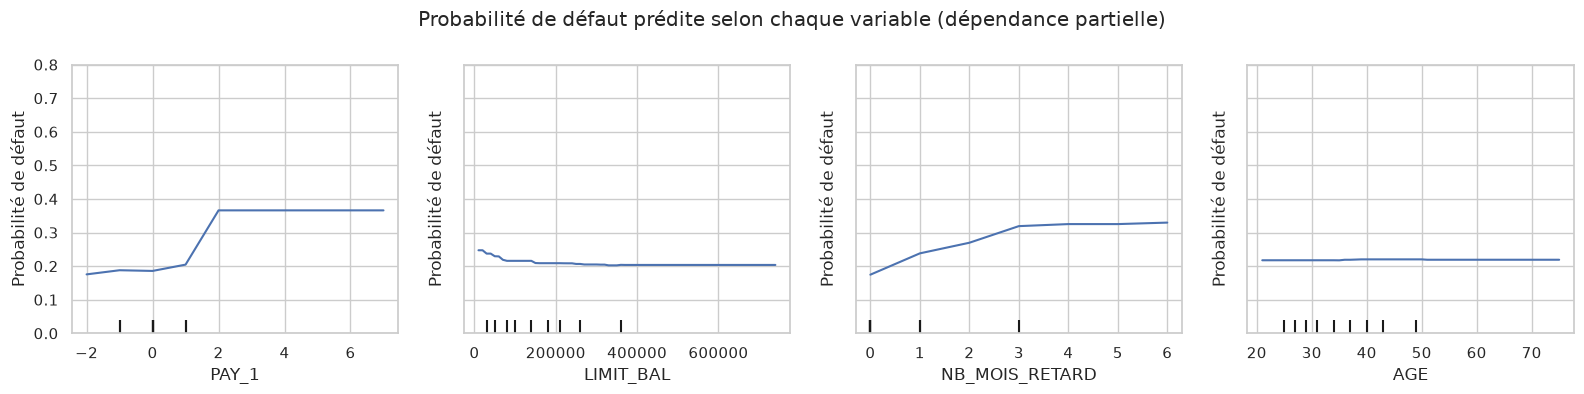

In [34]:
# On travaille sur un échantillon de 3 000 clients pour aller plus vite.
# .astype(float) : l'outil demande des nombres décimaux et non des entiers.
echantillon = X_train_plus.sample(3000, random_state=SEED).astype(float)

fig, ax = plt.subplots(figsize=(16, 4))
affichage = PartialDependenceDisplay.from_estimator(
    modele_final, echantillon, ['PAY_1', 'LIMIT_BAL', 'NB_MOIS_RETARD', 'AGE'],
    response_method='predict_proba', method='brute', ax=ax, n_cols=4)
for a in affichage.axes_[0]:
    a.set_ylabel('Probabilité de défaut')
    a.set_ylim(0, 0.8)
fig.suptitle('Probabilité de défaut prédite selon chaque variable (dépendance partielle)')
plt.tight_layout()
plt.show()

**Comment lire ces graphiques.** Pour chaque valeur de la variable (axe horizontal), on donne cette valeur à tous les clients de l'échantillon, sans rien changer d'autre, et on fait la moyenne des probabilités prédites. On mesure ainsi l'effet de la variable « toutes choses égales par ailleurs ». Les petits traits en bas indiquent où se trouvent la plupart des clients.

- **`PAY_1`** : la probabilité reste autour de 0,18 à 0,21 tant que le retard est d'au plus un mois, puis saute à 0,37 dès deux mois de retard, et ne bouge plus ensuite. Le modèle a appris un effet de seuil, exactement ce qu'une régression logistique ne savait pas représenter.
- **`LIMIT_BAL`** : le risque baisse de 0,25 à 0,20 quand le plafond passe de 10 000 à environ 100 000 NT$, puis reste stable. Au-delà, un plafond plus élevé ne change plus rien.
- **`NB_MOIS_RETARD`** : le risque monte de 0,18 (jamais en retard) à 0,24 avec un mois et 0,32 avec trois mois, puis plafonne.
- **`AGE`** : la courbe est plate. À comportement de paiement égal, l'âge ne change pas la prédiction.

Les effets paraissent plus faibles que les taux de défaut bruts de l'exploration. C'est normal : ici, les autres variables restent fixes, et une partie de l'information de `PAY_1` est déjà portée par `NB_MOIS_RETARD` et `RETARD_MAX`.

# 8. Récapitulatif

## 8.1 Tous les résultats

In [35]:
tous = pd.DataFrame(resultats).T.sort_values('AUC', ascending=False)
tous.round(3)

,AUC,Accuracy,Précision,Rappel,F1,Temps (s)
Gradient boosting réglé + variables,0.788,0.822,0.687,0.359,0.471,0.695
Vote (logistique + forêt + boosting),0.788,0.821,0.673,0.369,0.476,10.402
Gradient boosting réglé + variables + pondération,0.787,0.750,0.454,0.650,0.535,1.696
Gradient boosting + variables,0.786,0.820,0.677,0.361,0.471,0.617
Gradient boosting,0.784,0.820,0.676,0.360,0.470,0.512
Forêt aléatoire,0.779,0.818,0.659,0.367,0.471,4.190
Réseau de neurones,0.766,0.819,0.665,0.364,0.471,0.937
Régression logistique + variables,0.761,0.809,0.645,0.300,0.410,0.313
Arbre (profondeur 6),0.759,0.819,0.664,0.366,0.472,0.280
KNN (k=200),0.752,0.804,0.663,0.233,0.345,0.813


## 8.2 Les méthodes en une ligne

| Méthode | Idée en une phrase | Points forts | Points faibles | AUC ici |
|---|---|---|---|---|
| Régression logistique | Somme pondérée des variables, transformée en probabilité | Rapide, poids lisibles | Ne voit que des relations en ligne droite | 0,725 (0,761 avec les nouvelles variables) |
| KNN | Regarder les clients les plus ressemblants | Simple, aucune hypothèse | Lent à prédire, standardisation obligatoire | 0,752 |
| Bayésien naïf | Formule de Bayes en supposant les variables indépendantes | Quasi instantané | Probabilités exagérées si les variables sont liées | 0,734 |
| SVM | Frontière avec la plus grande marge | Efficace sur de petits jeux de données | Très lent sur de gros volumes, pas de probabilité | 0,720 |
| Arbre de décision | Suite de questions oui/non | Très lisible | Instable, surapprend vite | 0,759 |
| Forêt aléatoire | Moyenne de centaines d'arbres différents | Robuste, peu de réglages | Plus lente, moins lisible | 0,779 |
| Gradient boosting | Arbres en série, chacun corrige les précédents | Souvent le meilleur sur des tableaux, rapide | Plusieurs réglages, moins lisible | 0,784 (0,788 amélioré) |
| Réseau de neurones | Couches de neurones qui combinent les variables | Très puissant sur images, son, texte | Beaucoup de réglages, moins bon sur petits tableaux | 0,766 |

## 8.3 Ce qu'il faut retenir

**Le résultat.** Le meilleur modèle est un gradient boosting, avec cinq variables supplémentaires, des réglages optimisés et un seuil abaissé à 0,29. Sur 5 993 clients qu'il n'avait jamais vus, il obtient une AUC de 0,776 et détecte 56 % des défauts, avec une alerte juste sur deux.

**Les leçons de ce notebook :**

1. **Toujours comparer à une référence simple.** Le modèle naïf montre que l'accuracy est trompeuse, la règle `PAY_1 ≥ 1` donne le niveau à battre.
2. **Évaluer sur des données non vues.** La validation croisée pour comparer et régler, le test une seule fois à la fin. La courbe de l'arbre de décision montre ce qui arrive sinon.
3. **Les méthodes à base d'arbres dominent sur des données en tableau**, et le gradient boosting est en tête.
4. **Créer de bonnes variables aide surtout les modèles simples** : la régression logistique gagne près de 4 points d'AUC, le boosting presque rien.
5. **Régler les hyperparamètres et combiner les modèles apporte peu ici.** La limite vient de l'information disponible, pas des algorithmes.
6. **Le seuil de décision compte autant que le modèle.** À modèle identique, passer de 0,5 à 0,29 fait passer le rappel de 36 % à 57 %.

**Pour aller plus loin :**

- essayer les bibliothèques XGBoost et LightGBM, variantes du gradient boosting très utilisées en pratique ;
- tester le rééchantillonnage des classes (méthode SMOTE, bibliothèque `imbalanced-learn`), une troisième façon de traiter le déséquilibre ;
- régler le réseau de neurones (nombre de couches et de neurones) avec une recherche aléatoire, comme en 5.2 ;
- choisir le seuil à partir d'un coût réel par type d'erreur plutôt qu'avec le F1.